# Fashion Review Analytics: Will the customer recommend the product?
**Goal:** read a customer review and predict whether the customer would recommend the product, so the quality team can look at risky products first.

**Dataset:** Women's E-Commerce Clothing Reviews (Kaggle) – place `Womens Clothing E-Commerce Reviews.csv` 

# Step 1: NLP Fundamentals, Text Preprocessing & RegEx
## 1.1 Theory Notes
**What is NLP?** Natural Language Processing teaches computers to read and understand human language. Businesses need it because most customer feedback (reviews, emails, chats) is text, and no one can read lakhs of reviews by hand.

**3 real applications:** chatbots, search engines, review/sentiment analysis.

**4 challenges in NLP**
| Challenge | Example |
|---|---|
| Ambiguity | "The dress fits the model well" – does *fits* mean size or style? |
| Sarcasm | "Great, it fell apart after one wash." |
| Spelling mistakes | "Materal is very flimsey." |
| Hinglish code-mixing | "Kapda bahut cheap hai, size chhota." |

**Stages of a basic NLP pipeline:**
Raw text → Cleaning (lowercase, remove noise) → Tokenisation → Stop-word removal → Lemmatization → Feature extraction (BoW / TF-IDF / embeddings) → Model training → Prediction

## 1.2 Load, Handle Missing Text & Explore

In [1]:
import pandas as pd

df = pd.read_csv('dataset/Womens Clothing E-Commerce Reviews.csv', index_col=0)
df = df[['Title', 'Review Text', 'Rating', 'Recommended IND', 'Department Name']]

print(df.shape)
df.head(5)

(23486, 5)


,Title,Review Text,Rating,Recommended IND,Department Name
0,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,Intimate
1,NaN,Love this dress! it's sooo pretty. i happene...,5,1,Dresses
2,Some major design flaws,I had such high hopes for this dress and reall...,3,0,Dresses
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,Bottoms
4,Flattering shirt,This shirt is very flattering to all due to th...,5,1,Tops


In [2]:
df.isnull().sum()

Title              3810
Review Text         845
Rating                0
Recommended IND       0
Department Name      14
dtype: int64

Missing values are present mostly in `Title` and `Review Text`. A review without text cannot be analysed, so we drop those rows. A missing title is harmless, so we fill it with an empty string.

In [3]:
missing_text = df['Review Text'].isnull().sum()
print('Reviews with no Review Text:', missing_text)

df = df.dropna(subset=['Review Text'])
df['Title'] = df['Title'].fillna('')
df['full_text'] = df['Title'] + ' ' + df['Review Text']

print('Shape after cleaning:', df.shape)

Reviews with no Review Text: 845
Shape after cleaning: (22641, 6)


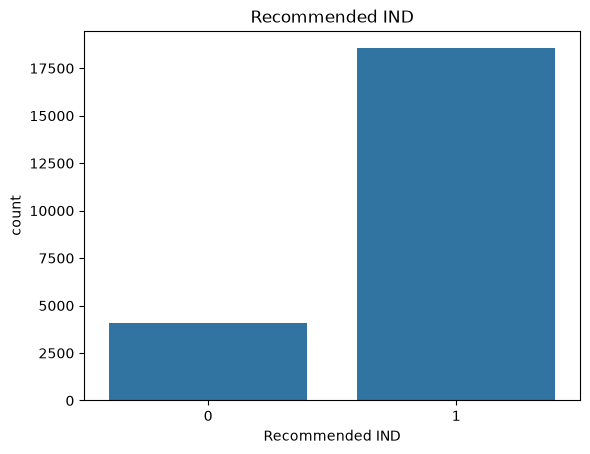

Not recommended: 18.1%
Baseline accuracy (always predict "recommends"): 0.819


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

target = 'Recommended IND'

sns.countplot(x=target, data=df)
plt.title('Recommended IND')
plt.show()

not_rec_rate = (df[target] == 0).mean() * 100
baseline_acc = (df[target] == 1).mean()
print(f'Not recommended: {not_rec_rate:.1f}%')
print(f'Baseline accuracy (always predict "recommends"): {baseline_acc:.3f}')

**Interpretation:** the data is imbalanced – only a small share of customers do not recommend. A model that always says *recommends* already looks accurate, so accuracy alone will not be a fair measure.

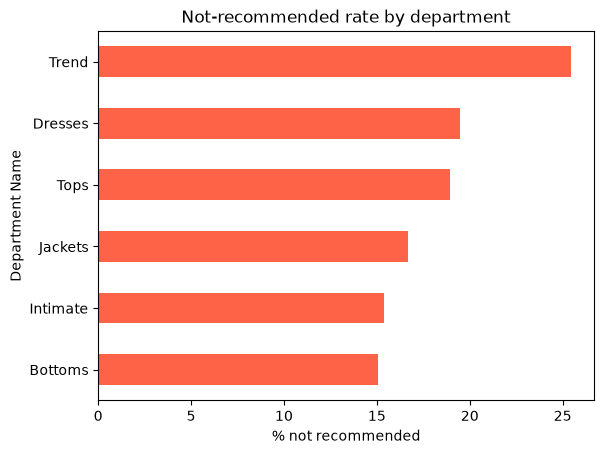

Highest rate: Trend (25.4%)


In [5]:
dept_rate = df.groupby('Department Name')[target].apply(lambda s: (s == 0).mean() * 100).sort_values()

dept_rate.plot(kind='barh', color='tomato')
plt.xlabel('% not recommended')
plt.title('Not-recommended rate by department')
plt.show()

top_dept = dept_rate.idxmax()
print('Highest rate:', top_dept, f'({dept_rate.max():.1f}%)')

**Interpretation:** the longest bar is the department where customers are least happy, so it needs the quality team's attention first.

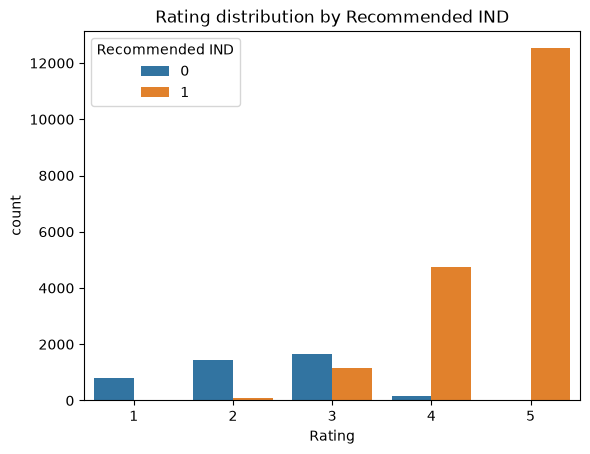

In [6]:
sns.countplot(x='Rating', hue=target, data=df)
plt.title('Rating distribution by Recommended IND')
plt.show()

**Interpretation:** high ratings (4-5) are mostly 'recommended' and low ratings (1-2) mostly 'not recommended'. The mid ratings are mixed, so rating alone cannot decide the label.

In [7]:
odd = df[(df['Rating'] >= 4) & (df[target] == 0)]
print('4-5 star reviews that are NOT recommended:', len(odd))

for text in odd['full_text'].sample(3, random_state=42):
    print('-', text[:250], '\n')

4-5 star reviews that are NOT recommended: 187
- Gorgeous, but... Everything about this dress is beautiful except for the hemline. the color is beautiful; the old-fashioned, wispy femininity is beautiful. the dress probably could use something better at the waistline besides elastic, maybe ribbons  

- Huge This is a gorgeous sweater but huge. and when i say huge, i mean gigantic. i'm usually a size large and i don't even think the small would be small enough. the cowl neck and fabric overall is great (although stretches out, which is why it become 

-  Material is kind of thick. stretchy. the orange i ordered was just too bright for me. i'm 8/10 and got the 10. i think the 8 would've worked better. sending back, mostly bc the color didn't look good on me. 



**Interpretation:** some customers give 4–5 stars but still do not recommend. Typical reasons: a mixed opinion ("nice colour but runs small"), or the rating was given for the look while the fit/quality was disappointing.

In [8]:
df['review_length'] = df['full_text'].str.split().str.len()
df.groupby(target)['review_length'].mean()

Recommended IND
0    65.211412
1    62.636785
Name: review_length, dtype: float64

**Interpretation:** compare the two averages above – longer reviews usually mean the customer has more to explain, which is common for complaints.

## 1.3 Train-Test Split (before fitting anything)

In [9]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df[target])
train = train.copy()
test = test.copy()

print('Train size:', len(train), '| Test size:', len(test))
print('Train class %:\n', (train[target].value_counts(normalize=True) * 100).round(1))
print('Test class %:\n', (test[target].value_counts(normalize=True) * 100).round(1))

Train size: 18112 | Test size: 4529
Train class %:
 Recommended IND
1    81.9
0    18.1
Name: proportion, dtype: float64
Test class %:
 Recommended IND
1    81.9
0    18.1
Name: proportion, dtype: float64


**Why split before fitting a vectoriser or embedding model?**
A vectoriser learns its vocabulary (and IDF weights) from the text it sees. If it sees the test reviews too, information from the test set leaks into training and the scores look better than they really are. This is called **data leakage**. So every `CountVectorizer`, `TfidfVectorizer` and `Word2Vec` is fitted on **training reviews only**; test reviews are only transformed.

## 1.4 Regular Expressions

In [10]:
import re

overall_rate = (train[target] == 0).mean() * 100

size_pattern = r'(?i)\b(?:xxs|xs|small|medium|large|xl|xxl)\b'
has_size = train['full_text'].str.contains(size_pattern, regex=True)

size_rate = (train.loc[has_size, target] == 0).mean() * 100
print('Reviews mentioning a size word:', has_size.sum())
print(f'Not-recommended rate in them: {size_rate:.1f}% vs overall {overall_rate:.1f}%')

Reviews mentioning a size word: 6342
Not-recommended rate in them: 18.1% vs overall 18.1%


In [11]:
height_pattern = r"\b[4-6]['’]\s?\d{0,2}"
has_height = train['full_text'].str.contains(height_pattern, regex=True)
print('Reviews mentioning a height:', has_height.sum())

for text in train.loc[has_height, 'full_text'].head(3):
    print('-', re.findall(height_pattern, text), '|', text[:150])

Reviews mentioning a height: 3420
- ["5'4"] | Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm 5'4", 140. it's a little roomy but will be n
- ["5'3"] | In love I am 5'3 and tried this dress on in both a large and medium petite. the dress is supposed to be a lose fit but i found that i was swimming in 
- ["5'7"] | Beautiful and cozy This is a beautiful sweater/tunic/dress. i ordered in the mustard color, and wearing it will brighten my day on a dreary winter mor


In [12]:
train['exclaim_count'] = train['full_text'].str.count(r'!')
train.groupby(target)['exclaim_count'].mean()

Recommended IND
0    0.423651
1    0.958128
Name: exclaim_count, dtype: float64

In [13]:
train['caps_count'] = train['full_text'].str.count(r'\b[A-Z]{3,}\b')
train.groupby(target)['caps_count'].mean()

Recommended IND
0    0.0
1    0.0
Name: caps_count, dtype: float64

**Interpretation:** if the not-recommended group has a higher average, it means unhappy customers use more capitals or exclamation marks to show strong feeling.

In [14]:
def replace_numbers(text):
    return re.sub(r'\d+', 'NUM', text)

def expand_not(text):
    text = text.replace('’', "'")
    text = re.sub(r"\bcan't\b", 'can not', text, flags=re.I)
    text = re.sub(r"\bwon't\b", 'will not', text, flags=re.I)
    return re.sub(r"n't\b", ' not', text, flags=re.I)

samples = train.loc[train['full_text'].str.contains(r"n't|\d", regex=True), 'full_text'].head(3)

for text in samples:
    print('BEFORE:', text[:200])
    print('AFTER :', expand_not(replace_numbers(text))[:200], '\n')

BEFORE: Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm 5'4", 140. it's a little roomy but will be nice over sweaters too. i love the cropped length. 
AFTER : Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm NUM'NUM", NUM. it's a little roomy but will be nice over sweaters too. i love the cropped leng 

BEFORE: Going back... I purchased this dress in the green, and while the print and material were lovely, the extra folds in the neckline made the dress look frumpy up top. the billowly bottom made it look lik
AFTER : Going back... I purchased this dress in the green, and while the print and material were lovely, the extra folds in the neckline made the dress look frumpy up top. the billowly bottom made it look lik 

BEFORE: Great staple! I ordered this a little big because the smallest size that they had was a medium. i probably could have gone with a small, but given that 

## 1.5 Text Preprocessing Pipeline

In [15]:
import nltk

for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'averaged_perceptron_tagger',
            'averaged_perceptron_tagger_eng', 'vader_lexicon']:
    nltk.download(pkg, quiet=True)

We keep `not`, `no` and `nor` as stop-word exceptions because they flip the meaning: *"not comfortable"* is negative, but removing *not* would leave *"comfortable"* (positive).

In [17]:
from text_utils import clean_text

train['clean_text'] = train['full_text'].apply(clean_text)
test['clean_text'] = test['full_text'].apply(clean_text)

for i in range(5):
    print('ORIGINAL:', train['full_text'].iloc[i][:200])
    print('CLEANED :', train['clean_text'].iloc[i][:200], '\n')

ORIGINAL: Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm 5'4", 140. it's a little roomy but will be nice over sweaters too. i love the cropped length. 
CLEANED : perfect fall jacket loved minute saw email got blue grey medium little roomy nice sweater love cropped length really well made 

ORIGINAL: Going back... I purchased this dress in the green, and while the print and material were lovely, the extra folds in the neckline made the dress look frumpy up top. the billowly bottom made it look lik
CLEANED : going back purchased dress green print material lovely extra fold neckline made dress look frumpy top billowly bottom made look like bag ft waist size fit make think run large returning dress 

ORIGINAL: Love these but color faded when washed I'm pretty disappointed in these. just bought the yellow pair and wore today for the first time. super cute and very comfortable. i was in love with them. they g
CLEANED : love color fad

## 1.6 Stemming vs Lemmatization

In [18]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ['fitting', 'fitted', 'dresses', 'flattering', 'shrunk', 'returned', 'wearing', 'better']
pd.DataFrame({
    'word': words,
    'porter_stem': [stemmer.stem(w) for w in words],
    'lemma (as noun)': [lemmatizer.lemmatize(w) for w in words],
    'lemma (as verb)': [lemmatizer.lemmatize(w, pos='v') for w in words],
})

,word,porter_stem,lemma (as noun),lemma (as verb)
0,fitting,fit,fitting,fit
1,fitted,fit,fitted,fit
2,dresses,dress,dress,dress
3,flattering,flatter,flattering,flatter
4,shrunk,shrunk,shrunk,shrink
5,returned,return,returned,return
6,wearing,wear,wearing,wear
7,better,better,better,better


**Stemming** chops word endings with fixed rules, so the result may not be a real word (*flattering → flatter*, but also odd cuts such as *dresses → dress* / *better → better*).
**Lemmatization** uses a dictionary and returns a real base word (*returned → return*).
It needs the **part of speech** because the same word has different lemmas: *wearing* as a verb → *wear*, but as a noun it stays *wearing*. The table above shows the difference between noun and verb lemmas.

## 1.7 Word Frequency

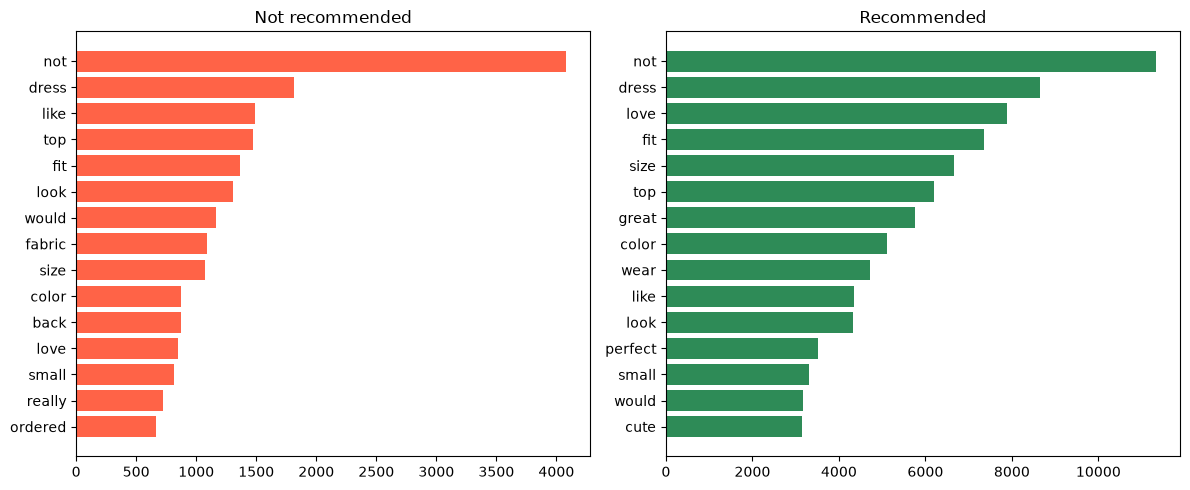

Words in both lists: {'not', 'top', 'size', 'would', 'fit', 'small', 'dress', 'like', 'love', 'look', 'color'}


In [19]:
from collections import Counter

def top_words(series, n=15):
    words = ' '.join(series).split()
    return Counter(words).most_common(n)

top_neg = top_words(train.loc[train[target] == 0, 'clean_text'])
top_pos = top_words(train.loc[train[target] == 1, 'clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title, color in zip(axes, [top_neg, top_pos],
                                  ['Not recommended', 'Recommended'], ['tomato', 'seagreen']):
    words, counts = zip(*data)
    ax.barh(words[::-1], counts[::-1], color=color)
    ax.set_title(title)
plt.tight_layout()
plt.show()

common = set(w for w, _ in top_neg) & set(w for w, _ in top_pos)
print('Words in both lists:', common)

**Interpretation:** words like *small*, *return*, *not* and *large* lean towards complaints, while *love*, *perfect*, *comfortable* lean towards happy customers. Words that appear in both lists (like *dress*, *fit*, *size*) are about the product itself, so they are weak signals on their own.

# Step 2: Feature Extraction – BoW, TF-IDF & N-Grams


## 2.1 Bag-of-Words on the tiny corpus

In [20]:
from sklearn.feature_extraction.text import CountVectorizer

docs = ['love this dress fits perfectly',
        'dress runs small and fits poorly',
        'great quality great fit',
        'not worth the price']

bow = CountVectorizer()
bow_matrix = bow.fit_transform(docs)

print(bow.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow.get_feature_names_out(),
                      index=['Doc 1', 'Doc 2', 'Doc 3', 'Doc 4'])
bow_df

['and' 'dress' 'fit' 'fits' 'great' 'love' 'not' 'perfectly' 'poorly'
 'price' 'quality' 'runs' 'small' 'the' 'this' 'worth']


,and,dress,fit,fits,great,love,not,perfectly,poorly,price,quality,runs,small,the,this,worth
Doc 1,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0
Doc 2,1,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0
Doc 3,0,0,1,0,2,0,0,0,0,0,1,0,0,0,0,0
Doc 4,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,1


Each number is how many times that word appears in that document. In Doc 3 the column *great* shows **2**. BoW ignores word order and grammar, so *dog bites man* and *man bites dog* look the same.

## 2.2 TF-IDF on the tiny corpus

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(docs)

tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out(),
                        index=['Doc 1', 'Doc 2', 'Doc 3', 'Doc 4']).round(2)
tfidf_df

,and,dress,fit,fits,great,love,not,perfectly,poorly,price,quality,runs,small,the,this,worth
Doc 1,0.00,0.38,0.00,0.38,0.00,0.49,0.0,0.49,0.00,0.0,0.00,0.00,0.00,0.0,0.49,0.0
Doc 2,0.44,0.34,0.00,0.34,0.00,0.00,0.0,0.00,0.44,0.0,0.00,0.44,0.44,0.0,0.00,0.0
Doc 3,0.00,0.00,0.41,0.00,0.82,0.00,0.0,0.00,0.00,0.0,0.41,0.00,0.00,0.0,0.00,0.0
Doc 4,0.00,0.00,0.00,0.00,0.00,0.00,0.5,0.00,0.00,0.5,0.00,0.00,0.00,0.5,0.00,0.5


In [22]:
print('dress  (in 2 docs) in Doc 1:', tfidf_df.loc['Doc 1', 'dress'])
print('quality (in 1 doc) in Doc 3:', tfidf_df.loc['Doc 3', 'quality'])

dress  (in 2 docs) in Doc 1: 0.38
quality (in 1 doc) in Doc 3: 0.41


**Comparison:** *quality* gets a higher weight than *dress* because it appears in only one document, so it is more special.

**TF** = how often a word appears in a document. **IDF** = how rare the word is across all documents.
`TF-IDF = TF × IDF`, where `IDF = log((1 + N) / (1 + df)) + 1` (scikit-learn version), N = number of documents, df = documents containing the word.
Common words get a low score, rare and meaningful words get a high score.

## 2.3 N-Grams

In [23]:
bigram = CountVectorizer(ngram_range=(2, 2))
bigram.fit(docs)
print('Bigrams:', bigram.get_feature_names_out()) 

Bigrams: ['and fits' 'dress fits' 'dress runs' 'fits perfectly' 'fits poorly'
 'great fit' 'great quality' 'love this' 'not worth' 'quality great'
 'runs small' 'small and' 'the price' 'this dress' 'worth the']


In [24]:
uni_bi = CountVectorizer(ngram_range=(1, 2))
uni_bi.fit(docs)
print('Unigrams + bigrams:', uni_bi.get_feature_names_out())

Unigrams + bigrams: ['and' 'and fits' 'dress' 'dress fits' 'dress runs' 'fit' 'fits'
 'fits perfectly' 'fits poorly' 'great' 'great fit' 'great quality' 'love'
 'love this' 'not' 'not worth' 'perfectly' 'poorly' 'price' 'quality'
 'quality great' 'runs' 'runs small' 'small' 'small and' 'the' 'the price'
 'this' 'this dress' 'worth' 'worth the']


The bigram **"not worth"** carries the real meaning of Doc 4. The single word *worth* alone looks positive, but the pair *not worth* is negative. Bigrams keep a little word order, so negation is not lost.

## 2.4 Features on real reviews (fit on training data only)

In [25]:
import numpy as np

def sparsity(matrix):
    return (1 - matrix.nnz / (matrix.shape[0] * matrix.shape[1])) * 100

cv = CountVectorizer(max_features=5000)
X_train_bow = cv.fit_transform(train['clean_text'])
X_test_bow = cv.transform(test['clean_text'])

print('Train BoW shape:', X_train_bow.shape, f'| sparsity: {sparsity(X_train_bow):.2f}%')
print('Test BoW shape :', X_test_bow.shape)

Train BoW shape: (18112, 5000) | sparsity: 99.46%
Test BoW shape : (4529, 5000)


In [26]:
tv = TfidfVectorizer(max_features=5000)
X_train_tfidf = tv.fit_transform(train['clean_text'])

print('Train TF-IDF shape:', X_train_tfidf.shape)

avg_score = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top10 = avg_score.argsort()[::-1][:10]
print('Top 10 words by average TF-IDF:', tv.get_feature_names_out()[top10])

Train TF-IDF shape: (18112, 5000)
Top 10 words by average TF-IDF: ['dress' 'not' 'love' 'top' 'fit' 'great' 'size' 'color' 'look' 'like']


In [27]:
bg = CountVectorizer(ngram_range=(2, 2), max_features=3000)
neg_text = train.loc[train[target] == 0, 'clean_text']
X_neg_bigram = bg.fit_transform(neg_text)

counts = np.asarray(X_neg_bigram.sum(axis=0)).ravel()
top_idx = counts.argsort()[::-1][:10]
for i in top_idx:
    print(bg.get_feature_names_out()[i], '->', counts[i])

wanted love -> 268
look like -> 235
not flattering -> 232
could not -> 192
not work -> 191
going back -> 185
looked like -> 161
would not -> 143
really wanted -> 133
dress not -> 122


**Interpretation:** the common bigrams in unhappy reviews point to the real complaints (size, fit, fabric quality, returning the item).

In [28]:
pd.DataFrame({
    'Method': ['Bag-of-Words', 'TF-IDF', 'Bigrams (not-recommended only)'],
    'Number of features': [X_train_bow.shape[1], X_train_tfidf.shape[1], X_neg_bigram.shape[1]],
    'Sparsity %': [round(sparsity(X_train_bow), 2), round(sparsity(X_train_tfidf), 2),
                   round(sparsity(X_neg_bigram), 2)],
})

,Method,Number of features,Sparsity %
0,Bag-of-Words,5000,99.46
1,TF-IDF,5000,99.46
2,Bigrams (not-recommended only),3000,99.69


**Reflection:** the test matrix must have exactly the same columns as the training matrix, because the model learned a weight for each training column. A test word that was never seen in training is simply ignored – it has no column.

# Step 3: Word Embeddings – Word2Vec (CBoW & Skip-gram)

## 3.1 Prepare tokens (training reviews only)

In [29]:
train['tokens'] = train['clean_text'].str.split()

print('Average tokens per review:', round(train['tokens'].str.len().mean(), 1))
print('Unique words:', len(set(w for toks in train['tokens'] for w in toks)))

Average tokens per review: 31.2
Unique words: 11497


## 3.2 Train CBoW and Skip-gram

In [30]:
from gensim.models import Word2Vec

sentences = train['tokens'].tolist()

cbow = Word2Vec(sentences=sentences, vector_size=100, window=5, min_count=5,
                sg=0, epochs=10, seed=42, workers=1)
skip = Word2Vec(sentences=sentences, vector_size=100, window=5, min_count=5,
                sg=1, epochs=10, seed=42, workers=1)

print('CBoW vocab:', len(cbow.wv), '| vector shape:', cbow.wv['dress'].shape)
print('Skip-gram vocab:', len(skip.wv), '| vector shape:', skip.wv['dress'].shape)

CBoW vocab: 3910 | vector shape: (100,)
Skip-gram vocab: 3910 | vector shape: (100,)


All 18,000+ training reviews were used (no subset needed).

## 3.3 Explore the embeddings

In [31]:
query_words = ['dress', 'small', 'comfortable', 'cheap', 'return']

for word in query_words:
    for name, model in [('CBoW', cbow), ('Skip-gram', skip)]:
        if word in model.wv:
            print(name, '|', word, '->', model.wv.most_similar(word, topn=5))
    print()

CBoW | dress -> [('wedding', 0.5158215165138245), ('maxi', 0.5056835412979126), ('jumper', 0.43625208735466003), ('occasion', 0.43296757340431213), ('graduation', 0.41326484084129333)]
Skip-gram | dress -> [('frock', 0.6654386520385742), ('creation', 0.6524582505226135), ('bridesmaid', 0.6385599374771118), ('wedding', 0.6375834941864014), ('elegantly', 0.6357769966125488)]

CBoW | small -> [('large', 0.8992555141448975), ('big', 0.7527366280555725), ('l', 0.7266308069229126), ('x', 0.6899229288101196), ('xsmall', 0.6700409650802612)]
Skip-gram | small -> [('large', 0.8658664226531982), ('xsmall', 0.7921815514564514), ('medium', 0.7500998377799988), ('swam', 0.7444099187850952), ('petit', 0.7335664629936218)]

CBoW | comfortable -> [('comfy', 0.8207278251647949), ('relaxed', 0.504777729511261), ('stretchy', 0.46385958790779114), ('wonderfully', 0.46025320887565613), ('buttery', 0.4594573378562927)]
Skip-gram | comfortable -> [('comfy', 0.7794689536094666), ('smart', 0.6887288093566895),

In [32]:
pairs = [('small', 'tight'), ('large', 'loose'), ('soft', 'comfortable'), ('love', 'hate')]

rows = []
for a, b in pairs:
    row = {'pair': f'{a} - {b}'}
    for name, model in [('CBoW', cbow), ('Skip-gram', skip)]:
        row[name] = round(model.wv.similarity(a, b), 3) if a in model.wv and b in model.wv else None
    rows.append(row)
pd.DataFrame(rows)

,pair,CBoW,Skip-gram
0,small - tight,0.533,0.513
1,large - loose,0.304,0.447
2,soft - comfortable,0.439,0.599
3,love - hate,0.068,0.413


In [33]:
def top3(model, word):
    return ', '.join(w for w, _ in model.wv.most_similar(word, topn=3)) if word in model.wv else '-'

pd.DataFrame({
    'Query word': query_words,
    'Top-3 CBoW': [top3(cbow, w) for w in query_words],
    'Top-3 Skip-gram': [top3(skip, w) for w in query_words],
})

,Query word,Top-3 CBoW,Top-3 Skip-gram
0,dress,"wedding, maxi, jumper","frock, creation, bridesmaid"
1,small,"large, big, l","large, xsmall, medium"
2,comfortable,"comfy, relaxed, stretchy","comfy, smart, uber"
3,cheap,"flimsy, shiny, awful","flimsy, shiny, blah"
4,return,"exchange, returning, returned","returning, returned, exchange"


**Interpretation:** Skip-gram usually gives more sensible neighbours on review data because it learns each word from its own context, which helps rarer words. *small* and *tight* end up close because they appear in the same kind of sentences ("runs small", "too tight") – they are used in the same contexts even though they are different words. Note that *love* and *hate* can also be close, as both are used in similar sentence positions.

## 3.4 Visualise Skip-gram vectors

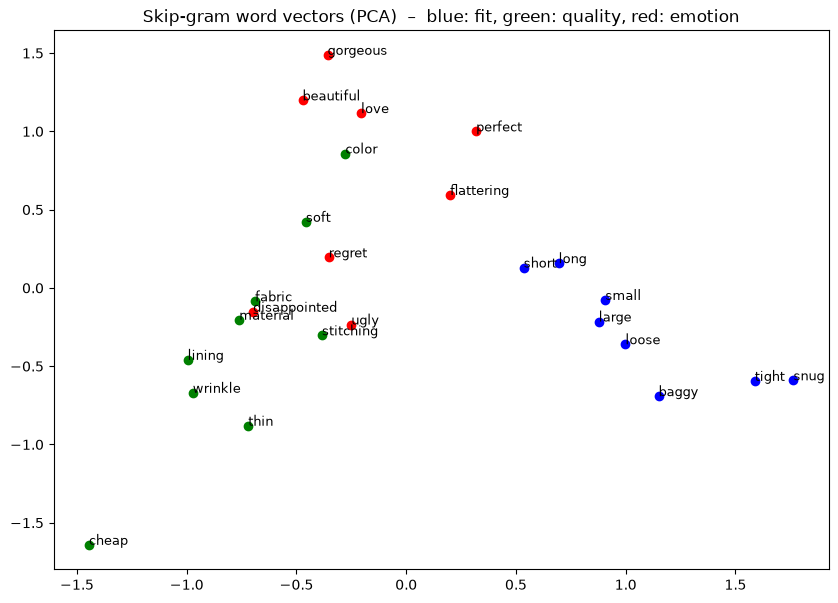

In [34]:
from sklearn.decomposition import PCA

groups = {
    'fit': ['small', 'large', 'tight', 'loose', 'short', 'long', 'snug', 'baggy'],
    'quality': ['fabric', 'material', 'soft', 'cheap', 'thin', 'stitching', 'color', 'lining', 'wrinkle'],
    'emotion': ['love', 'beautiful', 'gorgeous', 'disappointed', 'ugly', 'regret', 'perfect', 'flattering'],
}
colors = {'fit': 'blue', 'quality': 'green', 'emotion': 'red'}

plot_words = [(w, g) for g, ws in groups.items() for w in ws if w in skip.wv]
vectors = np.array([skip.wv[w] for w, _ in plot_words])
points = PCA(n_components=2, random_state=42).fit_transform(vectors)

plt.figure(figsize=(10, 7))
for (w, g), (x, y) in zip(plot_words, points):
    plt.scatter(x, y, color=colors[g])
    plt.annotate(w, (x, y), fontsize=9)
plt.title('Skip-gram word vectors (PCA)  –  blue: fit, green: quality, red: emotion')
plt.show()

**Interpretation:** words of the same kind tend to sit near each other – fit words in one area, emotion words in another. Clusters will not be perfect because the model was trained on reviews only.

## 3.5 Save & Reflect

In [35]:
skip.save('word2vec_skipgram.model')

- **CBoW** predicts a word from its surrounding context words; **Skip-gram** predicts the context words from one word.
- Skip-gram is better for **rare words** because every word gets its own training examples.
- A dense 100-number vector is more useful than a BoW vector because it is small, and similar words get similar vectors (BoW treats *small* and *tight* as completely unrelated).

# Step 4: Text Classification – Will the customer recommend?

## 4.1 Theory
**Text classification** means giving a piece of text a label (here: recommends / does not recommend).
**Stages:** collect data → clean text → split train/test → convert to features → train classifier → evaluate → save and use.

**Which error is worse?** For a returns team, missing an unhappy customer (**false negative**) is worse – a risky product goes unnoticed and returns continue. A false positive only costs a little time to inspect a product that was actually fine.

## 4.2 Baseline

In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_train = train[target]
y_test = test[target]

def evaluate(name, y_true, pred, prob_rec):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, pred),
        'Precision (0)': precision_score(y_true, pred, pos_label=0, zero_division=0),
        'Recall (0)': recall_score(y_true, pred, pos_label=0, zero_division=0),
        'F1 (0)': f1_score(y_true, pred, pos_label=0, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob_rec),
    }

base_pred = np.ones(len(y_test), dtype=int)
base_row = evaluate('Baseline (always 1)', y_test, base_pred, np.ones(len(y_test)) * 0.5)
base_row

{'Model': 'Baseline (always 1)',
 'Accuracy': 0.818944579377346,
 'Precision (0)': np.float64(0.0),
 'Recall (0)': np.float64(0.0),
 'F1 (0)': np.float64(0.0),
 'ROC-AUC': np.float64(0.5)}

**Interpretation:** accuracy is high but recall for class 0 is **0** – the baseline never catches a single unhappy customer, so it is useless for the business.

## 4.3 Build four classifiers

In [37]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def make_lr():
    return LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)

model_a = Pipeline([('vec', CountVectorizer(max_features=5000)), ('clf', make_lr())])
model_b = Pipeline([('vec', TfidfVectorizer(max_features=5000)), ('clf', make_lr())])
model_c = Pipeline([('vec', TfidfVectorizer(ngram_range=(1, 2), max_features=10000)), ('clf', make_lr())])

for model in [model_a, model_b, model_c]:
    model.fit(train['clean_text'], y_train)

In [38]:
def avg_vector(text, wv):
    words = [w for w in text.split() if w in wv.key_to_index]
    if len(words) == 0:
        return np.zeros(wv.vector_size)
    return np.mean([wv[w] for w in words], axis=0)

X_train_w2v = np.array([avg_vector(t, skip.wv) for t in train['clean_text']])
X_test_w2v = np.array([avg_vector(t, skip.wv) for t in test['clean_text']])

model_d = make_lr()
model_d.fit(X_train_w2v, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

## 4.4 Evaluate & compare

In [39]:
results = [base_row]
probs = {}   # probability of class 1 for each model

for name, model in [('A: Bag-of-Words', model_a), ('B: TF-IDF', model_b), ('C: TF-IDF + N-grams', model_c)]:
    probs[name] = model.predict_proba(test['clean_text'])[:, 1]
    results.append(evaluate(name, y_test, model.predict(test['clean_text']), probs[name]))

probs['D: Avg Word2Vec'] = model_d.predict_proba(X_test_w2v)[:, 1]
results.append(evaluate('D: Avg Word2Vec', y_test, model_d.predict(X_test_w2v), probs['D: Avg Word2Vec']))

results_df = pd.DataFrame(results).sort_values('Recall (0)', ascending=False).round(3)
results_df

,Model,Accuracy,Precision (0),Recall (0),F1 (0),ROC-AUC
4,D: Avg Word2Vec,0.866,0.586,0.885,0.706,0.941
3,C: TF-IDF + N-grams,0.890,0.645,0.876,0.743,0.948
2,B: TF-IDF,0.879,0.617,0.871,0.722,0.944
1,A: Bag-of-Words,0.885,0.647,0.796,0.714,0.926
0,Baseline (always 1),0.819,0.000,0.000,0.000,0.500


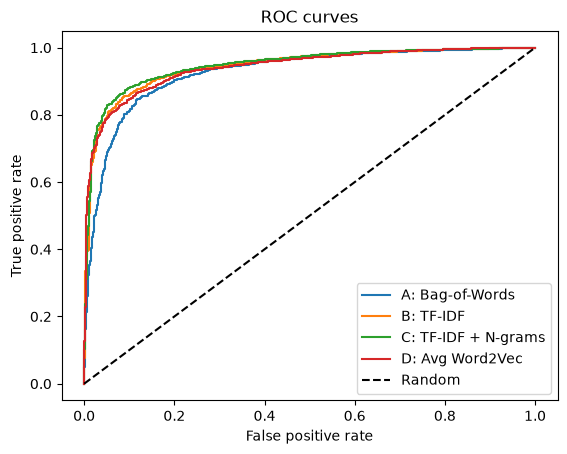

In [40]:
from sklearn.metrics import roc_curve

for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves')
plt.legend()
plt.show()

**Interpretation:** a curve closer to the top-left corner is better. The TF-IDF curves normally sit above Bag-of-Words and Word2Vec, and all are well above the dashed random line.

In [41]:
from sklearn.metrics import classification_report, confusion_matrix

pipelines = {'A: Bag-of-Words': model_a, 'B: TF-IDF': model_b, 'C: TF-IDF + N-grams': model_c}
best_name = max(pipelines, key=lambda n: roc_auc_score(y_test, probs[n]))
best_pipeline = pipelines[best_name]
best_pred = best_pipeline.predict(test['clean_text'])

print('Best pipeline:', best_name)
print(classification_report(y_test, best_pred, target_names=['Not recommended (0)', 'Recommended (1)']))

Best pipeline: C: TF-IDF + N-grams
                     precision    recall  f1-score   support

Not recommended (0)       0.65      0.88      0.74       820
    Recommended (1)       0.97      0.89      0.93      3709

           accuracy                           0.89      4529
          macro avg       0.81      0.88      0.84      4529
       weighted avg       0.91      0.89      0.90      4529



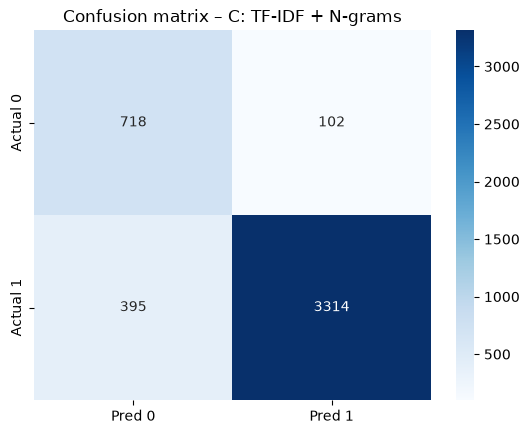

In [42]:
cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion matrix – ' + best_name)
plt.show()

**Interpretation:** the bottom-left box is happy customers wrongly flagged and the top-right box is unhappy customers missed. The top-left box (unhappy customers caught) should be as large as possible.

## 4.5 Choose a decision threshold

In [43]:
prob_not_rec = best_pipeline.predict_proba(test['clean_text'])[:, 0]

rows = []
for t in [0.3, 0.5, 0.7]:
    flagged = (prob_not_rec > t).astype(int)       # 1 = flagged as 'not recommended'
    actual_bad = (y_test == 0).astype(int)
    rows.append({
        'Threshold': t,
        'Precision (0)': precision_score(actual_bad, flagged, zero_division=0),
        'Recall (0)': recall_score(actual_bad, flagged, zero_division=0),
        'Reviews flagged': int(flagged.sum()),
    })
pd.DataFrame(rows).round(3)

,Threshold,Precision (0),Recall (0),Reviews flagged
0,0.3,0.508,0.960,1550
1,0.5,0.645,0.876,1113
2,0.7,0.763,0.678,729


**Interpretation:** a low threshold (0.3) catches more unhappy customers but flags many reviews; a high threshold (0.7) flags fewer, more certain ones. If the quality team can inspect only a limited number of reviews, a higher threshold such as **0.5–0.7** gives cleaner results; if missing a bad product is very costly, choose **0.3**.

## 4.6 Inspect & Save

In [44]:
vec = best_pipeline.named_steps['vec']
coef = best_pipeline.named_steps['clf'].coef_[0]
feature_names = vec.get_feature_names_out()
order = coef.argsort()

print('Strongest towards NOT recommended:', list(feature_names[order[:8]]))
print('Strongest towards RECOMMENDS     :', list(feature_names[order[::-1][:8]]))

Strongest towards NOT recommended: ['disappointed', 'wanted love', 'not flattering', 'not', 'returning', 'unflattering', 'returned', 'return']
Strongest towards RECOMMENDS     : ['love', 'perfect', 'great', 'comfortable', 'unique', 'soft', 'flattering', 'little']


In [45]:
wrong = test[best_pred != y_test.values].head(5)

for text, actual in zip(wrong['full_text'], wrong[target]):
    print('Actual:', actual, '|', text[:250], '\n')

Actual: 1 | Beautiful skirt, does run small I ordered this skirt in my usual xs. when it arrived it looked tiny. the xs was almost impossible to get on. i ended up returning the xs for a medium, which fit perfectly (and is work appropriate). my measurements are  

Actual: 0 | Just love... I usually wear a s. the reviews were helpful. looking at the pic this shirt does look a little on the fitted side. i ordered a size m & it fits perfectly! the sleeve length is fine too! the colors are dark, not as in the photo. i do like 

Actual: 0 | Peplum hits very high I'm 5'5" and i think fairly proportioned (120 lbs, 34b) and the peplum hit well above my waist. since having kids i'm a little obsessive about avoiding any shirt that could double as maternity... and this struck me as one. it's  

Actual: 0 | Delightful, different, gets dirty asap I love the design and fit and quality. have been looking for a long-line top like this and was willing to pay full price. i have that dreadful little roll

**Why they failed (check each one above):** typical reasons are a *mixed opinion* (praise and complaint together), *sarcasm*, a *very short review*, or a review that talks about a different product aspect than the label.

In [46]:
import joblib

joblib.dump(best_pipeline, 'recommend_pipeline.pkl')
loaded = joblib.load('recommend_pipeline.pkl')

new_reviews = [
    'Absolutely love this dress, the fabric is soft and it fits perfectly!',
    'Very disappointed. The material feels cheap and it runs too small.',
    'Lovely colour but runs very small, had to return it.',
    'Not worth the price, the stitching came apart after one wash.',
    'Comfortable and flattering, I would buy it again.',
]

from text_utils import clean_text
cleaned = [clean_text(r) for r in new_reviews]
labels = loaded.predict(cleaned)
prob_rec = loaded.predict_proba(cleaned)[:, 1]

for review, label, p in zip(new_reviews, labels, prob_rec):
    print(f'{label} | P(recommend)={p:.2f} | {review}')

1 | P(recommend)=0.98 | Absolutely love this dress, the fabric is soft and it fits perfectly!
0 | P(recommend)=0.02 | Very disappointed. The material feels cheap and it runs too small.
0 | P(recommend)=0.49 | Lovely colour but runs very small, had to return it.
0 | P(recommend)=0.05 | Not worth the price, the stitching came apart after one wash.
1 | P(recommend)=0.92 | Comfortable and flattering, I would buy it again.


# Step 5: Different NLP Approaches & POS Tagging

In [47]:
test_1000 = test.head(1000)
train_1000 = train.head(1000)
y_test_1000 = test_1000[target]
y_train_1000 = train_1000[target]

## 5.1 Approach 1 – Heuristic (rule-based)

In [48]:
warning_words = ['return', 'returned', 'disappointed', 'too small', 'too big', 'poor quality', 'cheap',
                 'itchy', 'see through', 'sheer', 'not worth', 'waste', 'uncomfortable', 'returning', 'ripped']

def count_warnings(text):
    text = text.lower()
    return sum(word in text for word in warning_words)

test_1000 = test_1000.assign(warn_count=test_1000['full_text'].apply(count_warnings))

def rule_metrics(min_hits):
    pred = (test_1000['warn_count'] < min_hits).astype(int)   # 0 if enough warning words
    return pred, accuracy_score(y_test_1000, pred), recall_score(y_test_1000, pred, pos_label=0), \
           f1_score(y_test_1000, pred, pos_label=0)

for hits in [1, 2]:
    _, acc, rec, f1 = rule_metrics(hits)
    print(f'Rule ">= {hits} warning words": accuracy={acc:.3f}, recall(0)={rec:.3f}, F1(0)={f1:.3f}')

Rule ">= 1 warning words": accuracy=0.783, recall(0)=0.390, F1(0)=0.396
Rule ">= 2 warning words": accuracy=0.817, recall(0)=0.159, F1(0)=0.241


In [49]:
best_hits = max([1, 2], key=lambda h: rule_metrics(h)[3])
heur_pred, heur_acc, heur_rec, heur_f1 = rule_metrics(best_hits)
print('Kept rule: at least', best_hits, 'warning word(s)')

Kept rule: at least 1 warning word(s)


In [50]:
# check the mistake mentioned in the exam: keyword fires although the customer is happy
false_alarm = test_1000[(heur_pred == 0) & (y_test_1000 == 1)]
print('Happy customers wrongly flagged by the rule:', len(false_alarm))
for text in false_alarm['full_text'].head(2):
    print('-', text[:200])

Happy customers wrongly flagged by the rule: 106
- Pretty...thin The shirt fits nice and has a classic cut. i would imagine this to look good on just about anyone. the shirt is soft and comfortable, but is rather thin and see through. the stitching is
- Beautiful skirt, does run small I ordered this skirt in my usual xs. when it arrived it looked tiny. the xs was almost impossible to get on. i ended up returning the xs for a medium, which fit perfect


## 5.2 Approach 2 – Ready-made tool (VADER)

In [51]:
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()
train_1000 = train_1000.assign(compound=train_1000['full_text'].apply(lambda t: sia.polarity_scores(t)['compound']))
test_1000 = test_1000.assign(compound=test_1000['full_text'].apply(lambda t: sia.polarity_scores(t)['compound']))

best_t, best_f1 = None, -1
for t in [0, 0.2, 0.4]:
    pred = (train_1000['compound'] >= t).astype(int)       # predict 0 if compound < t
    f1 = f1_score(y_train_1000, pred, pos_label=0)
    print(f't={t}: F1(0) on training 1000 = {f1:.3f}')
    if f1 > best_f1:
        best_t, best_f1 = t, f1
print('Best t:', best_t)

t=0: F1(0) on training 1000 = 0.324
t=0.2: F1(0) on training 1000 = 0.431
t=0.4: F1(0) on training 1000 = 0.467
Best t: 0.4


In [52]:
vader_pred = (test_1000['compound'] >= best_t).astype(int)
vader_acc = accuracy_score(y_test_1000, vader_pred)
vader_rec = recall_score(y_test_1000, vader_pred, pos_label=0)
vader_f1 = f1_score(y_test_1000, vader_pred, pos_label=0)
print(f'VADER: accuracy={vader_acc:.3f}, recall(0)={vader_rec:.3f}, F1(0)={vader_f1:.3f}')

VADER: accuracy=0.840, recall(0)=0.324, F1(0)=0.424


No model was trained here – we called a ready-made tool and only tuned one number (`t`), like using a sentiment API.

## 5.3 Approach 3 – Machine learning

In [53]:
ml_pred = loaded.predict(test_1000['clean_text'])
ml_acc = accuracy_score(y_test_1000, ml_pred)
ml_rec = recall_score(y_test_1000, ml_pred, pos_label=0)
ml_f1 = f1_score(y_test_1000, ml_pred, pos_label=0)

pd.DataFrame({
    'Approach': ['Heuristic', 'VADER', 'ML (TF-IDF + LR)'],
    'Needs training data?': ['No', 'No (only tune t)', 'Yes'],
    'Accuracy': [heur_acc, vader_acc, ml_acc],
    'Recall (0)': [heur_rec, vader_rec, ml_rec],
    'F1 (0)': [heur_f1, vader_f1, ml_f1],
    'Advantage': ['Very easy to explain', 'Ready to use in minutes', 'Learns patterns from data'],
    'Disadvantage': ['Misses context, hand-made list', 'Generic sentiment, not our label', 'Needs labelled data and training'],
}).round(3)

,Approach,Needs training data?,Accuracy,Recall (0),F1 (0),Advantage,Disadvantage
0,Heuristic,No,0.783,0.390,0.396,Very easy to explain,"Misses context, hand-made list"
1,VADER,No (only tune t),0.840,0.324,0.424,Ready to use in minutes,"Generic sentiment, not our label"
2,ML (TF-IDF + LR),Yes,0.892,0.879,0.748,Learns patterns from data,Needs labelled data and training


**Interpretation:** the ML model usually gives the best balance of recall and F1. Choose the **heuristic** for a quick first version or when there is no labelled data, **VADER** when you need a fast general sentiment signal, and **ML** when you have labelled data and need quality. The heuristic is the easiest to explain to a business manager, since it is just a list of warning words.

## 5.4 POS Tagging

In [54]:
my_reviews = [
    'The dress is beautiful but the fabric feels cheap.',
    'I love the perfect fit and the soft material.',
    'It runs very small and the stitching is poor.',
    'She did not return this lovely top.',
    'Great quality and a comfortable length.',
]

rows = []
for i, review in enumerate(my_reviews, 1):
    for word, tag in nltk.pos_tag(nltk.word_tokenize(review)):
        rows.append({'Review': i, 'Word': word, 'POS Tag': tag})

pd.DataFrame(rows).head(25)

,Review,Word,POS Tag
0,1,The,DT
1,1,dress,NN
2,1,is,VBZ
3,1,beautiful,JJ
4,1,but,CC
5,1,the,DT
6,1,fabric,JJ
7,1,feels,NNS
8,1,cheap,VBP
9,1,.,.


| Tag | Meaning | Example |
|---|---|---|
| NN | singular noun | dress |
| NNS | plural noun | sizes |
| VB | verb, base form | fit |
| VBD | verb, past tense | returned |
| JJ | adjective | cheap |
| RB | adverb | very |
| PRP | personal pronoun | it |
| IN | preposition / conjunction | of |

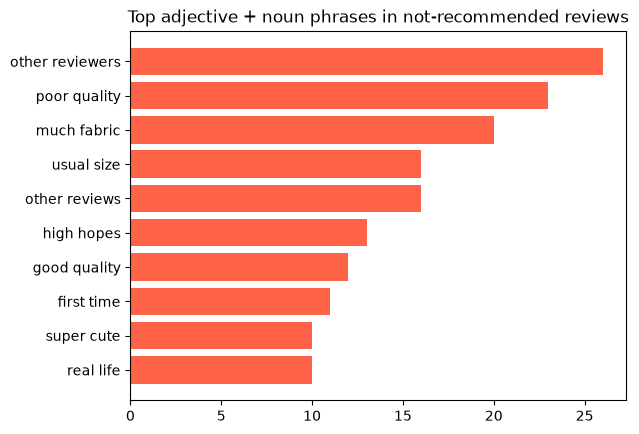

Highest not-recommended department from Step 1: Trend


In [55]:
neg_reviews = train.loc[train[target] == 0, 'full_text'].head(1000).str.lower()

phrases = []
for review in neg_reviews:
    tagged = nltk.pos_tag(nltk.word_tokenize(review))
    for (w1, t1), (w2, t2) in zip(tagged, tagged[1:]):
        if t1 == 'JJ' and t2 in ('NN', 'NNS'):
            phrases.append(w1 + ' ' + w2)

top_phrases = Counter(phrases).most_common(10)
labels_, values_ = zip(*top_phrases)

plt.barh(labels_[::-1], values_[::-1], color='tomato')
plt.title('Top adjective + noun phrases in not-recommended reviews')
plt.show()
print('Highest not-recommended department from Step 1:', top_dept)

**Interpretation:** the phrases show what customers complain about (for example size, quality or fabric words). The quality team should first check these issues in the department with the highest not-recommended rate (printed above).

# Final Interpretation
- About **1 in 5 customers do not recommend** the product, so accuracy alone is misleading; the "always recommends" baseline has high accuracy but **zero recall** for unhappy customers.
- **TF-IDF based models** (especially with bigrams) gave the best balance of recall, F1 and ROC-AUC; averaged Word2Vec was weaker.
- `class_weight='balanced'` and a lower **decision threshold** help catch more unhappy customers, at the cost of more reviews to inspect.
- The **ML pipeline beat the simple heuristic and VADER**, but those two need no training data and are easy to explain.
- **POS phrases** (adjective + noun) show what customers complain about, helping the quality team decide what to check first.
- The Streamlit app turns the saved pipeline into a tool the quality team can use on any new review.